# 02 - Selecao de Features

Seleciona as features de cada modelo do IDS em duas etapas:

- **Modelo 1 (binario):** BENIGN x Ataque
- **Modelo 2 (tipo de ataque):** DDoS, PortScan, WebAttack, SQLInjection

Ordem do processo:

1. Limpeza e remocao de duplicatas (`src/data.py`), incluindo as features removidas por decisao de dominio:
   colunas constantes, colunas identicas a outras, atalhos (`Destination Port`, `Init_Win_bytes_*`) e as
   flags TCP, que o CICFlowMeter original calcula errado e nao sao reproduziveis na deteccao ao vivo.
2. Divisao treino/teste estratificada. **O teste nao e usado neste notebook.**
3. Para cada modelo, no treino:
   - ranking inicial por importancia SHAP do XGBoost;
   - remocao de features muito correlacionadas (|r| > 0.95), mantendo a mais importante;
   - novo ranking e curva de F1 (validacao cruzada) x numero de features;
   - escolha do menor k cujo F1 fica a no maximo um desvio padrao do melhor.

## 1. Setup

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

from src.data import build_dataset, train_test, split_xy, DROP_COLUMNS
from src.features import (make_model, sample_weights, shap_importance, gain_importance,
                          correlation_filter, stratified_sample, topk_curve, choose_k)
from src.pipeline import MODELS_DIR

In [2]:
def plot_ranking(shap_rank, gain_rank, titulo, n=20):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    shap_rank.head(n)[::-1].plot.barh(ax=axes[0], color='steelblue')
    axes[0].set_title(f'{titulo} - SHAP (media |valor|)')
    gain_rank.head(n)[::-1].plot.barh(ax=axes[1], color='gray')
    axes[1].set_title(f'{titulo} - Gain')
    plt.tight_layout()
    plt.show()


def plot_curve(curve, k, titulo, metrica):
    plt.figure(figsize=(9, 5))
    plt.errorbar(curve['k'], curve['f1'], yerr=curve['std'], marker='o', capsize=3)
    plt.axvline(k, color='red', linestyle='--', label=f'k escolhido = {k}')
    plt.title(f'{titulo} - {metrica} x numero de features')
    plt.xlabel('Numero de features (top-k do ranking)')
    plt.ylabel(metrica)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def ks_para(n_features):
    return [k for k in [2, 3, 5, 8, 10, 12, 15, 20, 25, 30] if k < n_features] + [n_features]

## 2. Dados

In [3]:
df = build_dataset()
train, test = train_test(df)
X, y_bin, y_type = split_xy(train)

print('Dataset limpo e sem duplicatas:', df.shape)
print('Colunas removidas por decisao de dominio:', len(DROP_COLUMNS))
print('Features candidatas:', X.shape[1])
print('\nTreino por tipo:')
print(train['attack_type'].value_counts())

Dataset limpo e sem duplicatas: (453525, 54)
Colunas removidas por decisao de dominio: 26
Features candidatas: 52

Treino por tipo:
attack_type
BENIGN          257286
DDoS            102393
WebAttack         1596
PortScan          1535
SQLInjection        10
Name: count, dtype: int64


## 3. Modelo 1 - BENIGN x Ataque

As classes estao razoavelmente equilibradas no treino, entao este modelo nao usa pesos por classe.

### 3.1 Ranking inicial (todas as features)

SHAP mede quanto cada feature muda a previsao, em media. O *gain* (importancia padrao do XGBoost)
aparece ao lado so para comparacao: ele costuma superestimar features usadas em poucas divisoes.

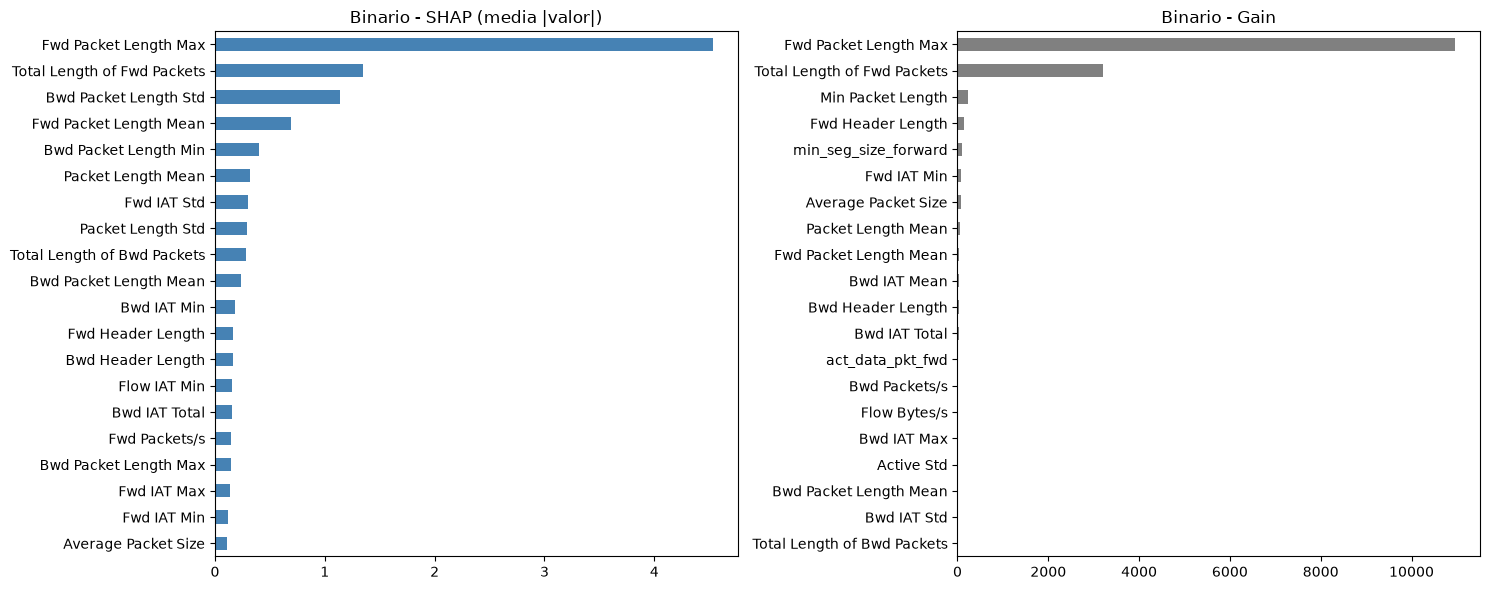

In [4]:
modelo = make_model(2)
modelo.fit(X, y_bin)

X_amostra_bin, _ = stratified_sample(X, y_bin, 5000)
rank_bin = shap_importance(modelo, X_amostra_bin)
plot_ranking(rank_bin, gain_importance(modelo, X.columns), 'Binario')

### 3.2 Remocao de features correlacionadas

In [5]:
kept_bin, dropped_bin = correlation_filter(X, rank_bin)
print(f'Mantidas: {len(kept_bin)} | Removidas: {len(dropped_bin)}')
pd.Series(dropped_bin, name='correlacionada com (mantida)').to_frame()

Mantidas: 35 | Removidas: 17


,correlacionada com (mantida)
Packet Length Std,Packet Length Mean
Bwd Packet Length Mean,Bwd Packet Length Std
Fwd Header Length,Total Length of Bwd Packets
Bwd Header Length,Total Length of Bwd Packets
Bwd Packet Length Max,Bwd Packet Length Std
Average Packet Size,Packet Length Mean
Fwd Packet Length Std,Fwd Packet Length Max
Flow Duration,Fwd IAT Total
Flow IAT Max,Fwd IAT Max
act_data_pkt_fwd,Total Length of Bwd Packets


### 3.3 Ranking final e curva F1 x numero de features

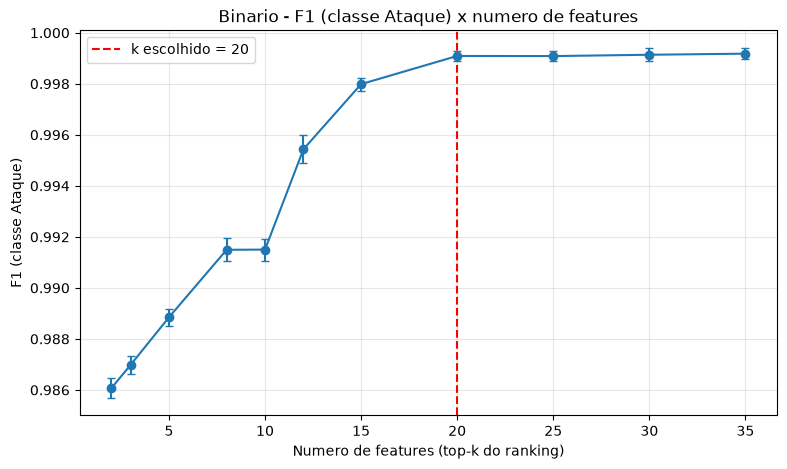

,k,f1,std
0,2,0.986070,0.000384
1,3,0.986979,0.000337
2,5,0.988849,0.000328
3,8,0.991493,0.000450
4,10,0.991502,0.000428
5,12,0.995436,0.000548
6,15,0.997986,0.000255
7,20,0.999090,0.000205
8,25,0.999085,0.000198
9,30,0.999138,0.000250


In [6]:
modelo = make_model(2)
modelo.fit(X[kept_bin], y_bin)
rank_bin = shap_importance(modelo, X_amostra_bin[kept_bin])

curve_bin = topk_curve(X, y_bin, rank_bin, ks_para(len(kept_bin)), balanced=False)
k_bin = choose_k(curve_bin)
features_bin = list(rank_bin.index[:k_bin])

plot_curve(curve_bin, k_bin, 'Binario', 'F1 (classe Ataque)')
curve_bin

In [7]:
print(f'{k_bin} features selecionadas para o modelo binario:')
rank_bin.head(k_bin).rename('SHAP').to_frame()

20 features selecionadas para o modelo binario:


,SHAP
Fwd Packet Length Max,3.877113
Total Length of Fwd Packets,1.405922
Bwd Packet Length Std,1.355569
Fwd Packet Length Mean,1.246280
Packet Length Mean,0.486671
Bwd Packet Length Min,0.370780
Fwd IAT Std,0.331712
Bwd IAT Total,0.305707
Total Length of Bwd Packets,0.281892
Packet Length Variance,0.268086


## 4. Modelo 2 - Tipo de ataque

Treinado so com fluxos de ataque. Aqui o desequilibrio e extremo (DDoS tem dezenas de milhares
de linhas, SQLInjection tem 11 no treino), entao o modelo usa **pesos por classe** (`balanced`)
e a metrica e o **F1 macro**, que da o mesmo peso a todas as classes.

In [8]:
ataques = y_bin == 1
X_att = X[ataques]
le = LabelEncoder()
y_att = pd.Series(le.fit_transform(y_type[ataques]), index=X_att.index)

print('Classes:', list(le.classes_))
print(y_type[ataques].value_counts())

Classes: ['DDoS', 'PortScan', 'SQLInjection', 'WebAttack']
attack_type
DDoS            102393
WebAttack         1596
PortScan          1535
SQLInjection        10
Name: count, dtype: int64


### 4.1 Ranking inicial (todas as features)

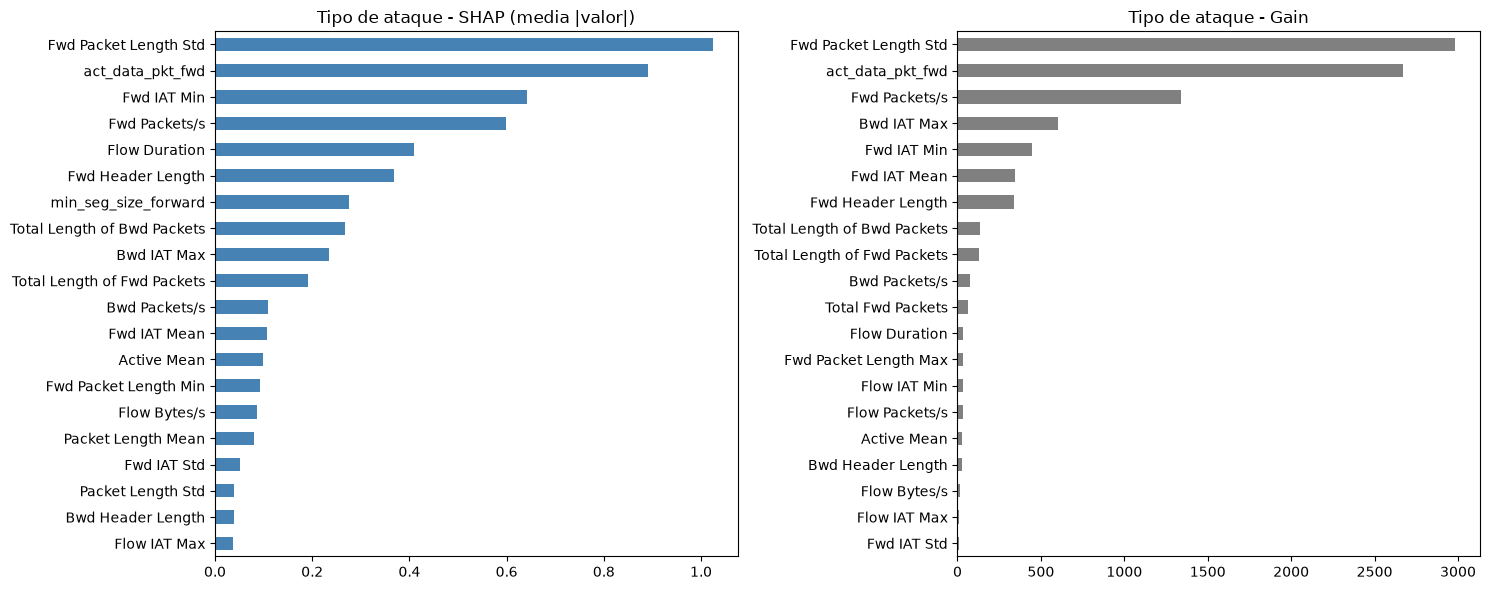

In [9]:
modelo = make_model(y_att.nunique())
modelo.fit(X_att, y_att, sample_weight=sample_weights(y_att, balanced=True))

X_amostra_att, _ = stratified_sample(X_att, y_att, 5000)
rank_att = shap_importance(modelo, X_amostra_att)
plot_ranking(rank_att, gain_importance(modelo, X_att.columns), 'Tipo de ataque')

### 4.2 Remocao de features correlacionadas

In [10]:
kept_att, dropped_att = correlation_filter(X_att, rank_att)
print(f'Mantidas: {len(kept_att)} | Removidas: {len(dropped_att)}')
pd.Series(dropped_att, name='correlacionada com (mantida)').to_frame()

Mantidas: 27 | Removidas: 25


,correlacionada com (mantida)
Bwd IAT Max,Fwd IAT Min
Total Length of Fwd Packets,Fwd Header Length
Fwd IAT Std,Flow Duration
Flow IAT Max,Flow Duration
Flow Packets/s,Fwd Packets/s
Flow IAT Std,Flow Duration
Bwd IAT Mean,Fwd IAT Min
Bwd IAT Min,Fwd IAT Min
Flow IAT Mean,Fwd IAT Mean
Fwd Packet Length Max,Fwd Packet Length Std


### 4.3 Ranking final e curva F1 macro x numero de features

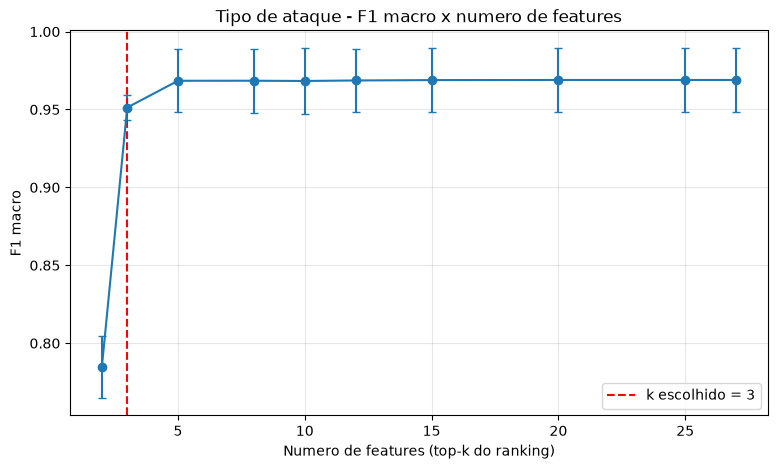

,k,f1,std
0,2,0.784763,0.019942
1,3,0.951271,0.007855
2,5,0.968443,0.020114
3,8,0.968461,0.020446
4,10,0.968309,0.021012
5,12,0.968629,0.020473
6,15,0.968871,0.020602
7,20,0.968949,0.020527
8,25,0.968949,0.020527
9,27,0.968949,0.020527


In [11]:
modelo = make_model(y_att.nunique())
modelo.fit(X_att[kept_att], y_att, sample_weight=sample_weights(y_att, balanced=True))
rank_att = shap_importance(modelo, X_amostra_att[kept_att])

curve_att = topk_curve(X_att, y_att, rank_att, ks_para(len(kept_att)), balanced=True)
k_att = choose_k(curve_att)
features_att = list(rank_att.index[:k_att])

plot_curve(curve_att, k_att, 'Tipo de ataque', 'F1 macro')
curve_att

In [12]:
print(f'{k_att} features selecionadas para o modelo de tipo de ataque:')
rank_att.head(k_att).rename('SHAP').to_frame()

3 features selecionadas para o modelo de tipo de ataque:


,SHAP
act_data_pkt_fwd,1.017465
Fwd Packet Length Std,0.992599
Fwd IAT Min,0.746122


## 5. Salvar selecao

In [13]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
for nome, features, curve, k in [('binario', features_bin, curve_bin, k_bin),
                                 ('tipo_ataque', features_att, curve_att, k_att)]:
    linha = curve.set_index('k').loc[k]
    with open(MODELS_DIR / f'selecao_features_{nome}.json', 'w', encoding='utf-8') as f:
        json.dump({'features': features, 'f1_cv': round(float(linha['f1']), 6),
                   'f1_cv_std': round(float(linha['std']), 6)}, f, indent=2, ensure_ascii=False)

print('Em comum entre os dois modelos:', sorted(set(features_bin) & set(features_att)))

Em comum entre os dois modelos: ['Fwd IAT Min']
